
# Portofolio Data Analyst: Analisis Kinerja Call Center

Proyek ini bertujuan untuk menganalisis efisiensi operasional call center, mengidentifikasi kualitas layanan pelanggan, serta memvalidasi keakuratan metrik yang dilaporkan dalam dataset.

### Tahapan Analisis:
1. **Data Loading & Inspection**: Memuat data dan memahami struktur awal.
2. **Data Cleaning & Transformation**: Pembersihan data duplikat, konversi waktu ke format detik, dan penanganan nilai kosong.
3. **Feature Engineering**: Validasi metrik persentase (seperti tingkat jawaban) untuk mendeteksi anomali data.
4. **Executive Summary & Insights**: Menarik kesimpulan penting untuk keputusan bisnis

## Tahap 1: Data Loading & Inspection
Langkah pertama adalah memuat dataset dan memeriksa sekilas isi data untuk menentukan kolom apa saja yang membutuhkan pembersihan.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Memuat dataset
df_raw = pd.read_csv("Call Center Data.csv")

# Menampilkan informasi umum dataset
print("=== Struktur Data Awal ===")
df_raw.info()
print("\n=== Contoh 5 Data Pertama ===")
display(df_raw.head())

=== Struktur Data Awal ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1251 entries, 0 to 1250
Data columns (total 9 columns):
 #   Column                      Non-Null Count  Dtype 
---  ------                      --------------  ----- 
 0   Index                       1251 non-null   int64 
 1   Incoming Calls              1251 non-null   int64 
 2   Answered Calls              1251 non-null   int64 
 3   Answer Rate                 1251 non-null   object
 4   Abandoned Calls             1251 non-null   int64 
 5   Answer Speed (AVG)          1251 non-null   object
 6   Talk Duration (AVG)         1251 non-null   object
 7   Waiting Time (AVG)          1251 non-null   object
 8   Service Level (20 Seconds)  1251 non-null   object
dtypes: int64(4), object(5)
memory usage: 88.1+ KB

=== Contoh 5 Data Pertama ===


,Index,Incoming Calls,Answered Calls,Answer Rate,Abandoned Calls,Answer Speed (AVG),Talk Duration (AVG),Waiting Time (AVG),Service Level (20 Seconds)
0,1,217,204,94.01%,13,0:00:17,0:02:14,0:02:45,76.28%
1,2,200,182,91.00%,18,0:00:20,0:02:22,0:06:55,72.73%
2,3,216,198,91.67%,18,0:00:18,0:02:38,0:03:50,74.30%
3,4,155,145,93.55%,10,0:00:15,0:02:29,0:03:12,79.61%
4,5,37,37,100.00%,0,0:00:03,0:02:06,0:00:35,97.30%


## Tahap 2: Data Cleaning & Transformation
Berdasarkan pemeriksaan awal, kita menemukan beberapa hal yang harus dibenahi:
- Menghapus baris duplikat berdasarkan kolom `Index`.
- Mengubah kolom waktu berformat `MM:SS` atau `HH:MM:SS` menjadi angka numerik dalam satuan **detik** agar bisa dihitung rata-ratanya.
- Mengubah persentase berformat teks menjadi tipe angka desimal.
- Menangani nilai yang missing values.

In [4]:
# Fungsi pembantu untuk mengubah string waktu menjadi detik
def duration_to_seconds(value):
    if pd.isna(value):
        return np.nan
    parts = str(value).strip().split(":")
    try:
        if len(parts) == 3:
            h, m, s = map(int, parts)
            return h * 3600 + m * 60 + s
        elif len(parts) == 2:
            m, s = map(int, parts)
            return m * 60 + s
    except ValueError:
        return np.nan
    return np.nan

# Salin data untuk proses cleaning
df_clean = df_raw.copy()

# 1. Hapus duplikat
df_clean = df_clean.drop_duplicates(subset=["Index"], keep="first")

# 2. Bersihkan karakter '%' pada kolom persentase
for col in ["Answer Rate", "Service Level (20 Seconds)"]:
    df_clean[col] = pd.to_numeric(df_clean[col].astype(str).str.replace("%", "", regex=False), errors="coerce")

# 3. Konversi durasi waktu ke detik
duration_cols = {
    "Answer Speed (AVG)": "Answer Speed Seconds",
    "Talk Duration (AVG)": "Talk Duration Seconds",
    "Waiting Time (AVG)": "Waiting Time Seconds"
}
for src, target in duration_cols.items():
    df_clean[target] = df_clean[src].apply(duration_to_seconds)

# 4. Pastikan kolom panggilan berupa numerik dan hapus baris yang kosong pada kolom kunci
key_numeric_cols = ["Index", "Incoming Calls", "Answered Calls", "Abandoned Calls"]
for col in key_numeric_cols:
    df_clean[col] = pd.to_numeric(df_clean[col], errors="coerce")

df_clean = df_clean.dropna(subset=["Index", "Incoming Calls", "Answered Calls", "Abandoned Calls"])

print(f"Data berhasil dibersihkan. Jumlah baris setelah cleaning: {len(df_clean)}")

Data berhasil dibersihkan. Jumlah baris setelah cleaning: 1251


## Tahap 3: Feature Engineering & Validasi Metrik
Validasi apakah data yang dilaporkan sudah akurat. Kita akan menghitung ulang `Answer Rate` dan `Abandon Rate` secara matematis untuk mencocokkannya dengan metrik bawaan sistem. Menghitung ulang persentase tingkat jawaban (Answer Rate) secara manual lalu membandingkannya dengan metrik bawaan sistem. Selisih hasil yang sangat kecil (mendekati 0%) membuktikan bahwa tidak ada manipulasi data dan perbedaan yang terjadi hanya karena pembulatan desimal otomatis dari sistem.

In [5]:
# Menghitung panggilan yang tidak terjawab secara manual
df_clean["Not Answered Calls (Calculated)"] = df_clean["Incoming Calls"] - df_clean["Answered Calls"]

# Hitung ulang persentase tingkat jawaban (Answer Rate) & tingkat penolakan (Abandon Rate)
df_clean["Answer Rate (Calculated %)"] = np.where(
    df_clean["Incoming Calls"] > 0,
    (df_clean["Answered Calls"] / df_clean["Incoming Calls"]) * 100,
    np.nan
)

df_clean["Abandon Rate (Calculated %)"] = np.where(
    df_clean["Incoming Calls"] > 0,
    (df_clean["Abandoned Calls"] / df_clean["Incoming Calls"]) * 100,
    np.nan
)

# Selisih antara Answer Rate bawaan data dengan hasil kalkulasi kita (untuk mendeteksi anomali)
df_clean["Answer Rate Difference (pp)"] = df_clean["Answer Rate"] - df_clean["Answer Rate (Calculated %)"]

print("Statistik Deskriptif Selisih Metrik (dalam %):")
print(df_clean["Answer Rate Difference (pp)"].describe())

Statistik Deskriptif Selisih Metrik (dalam %):
count    1251.000000
mean        0.000175
std         0.002824
min        -0.004959
25%        -0.002186
50%         0.000000
75%         0.002517
max         0.005000
Name: Answer Rate Difference (pp), dtype: float64


## Tahap 4: Ringkasan Eksekutif & Visualisasi Distribusi




In [6]:
# Hitung metrik keseluruhan (Weighted Metrics)
total_incoming = df_clean["Incoming Calls"].sum()
total_answered = df_clean["Answered Calls"].sum()
total_abandoned = df_clean["Abandoned Calls"].sum()
weighted_answer_rate = (total_answered / total_incoming) * 100
avg_answer_speed = df_clean["Answer Speed Seconds"].mean()
avg_waiting_time = df_clean["Waiting Time Seconds"].mean()
avg_service_level = df_clean["Service Level (20 Seconds)"].mean()

summary_data = {
    "Metric": [
        "Total Incoming Calls",
        "Total Answered Calls",
        "Total Abandoned Calls",
        "Weighted Answer Rate (%)",
        "Average Answer Speed (seconds)",
        "Average Waiting Time (seconds)",
        "Average Service Level within 20s (%)"
    ],
    "Value": [
        total_incoming,
        total_answered,
        total_abandoned,
        weighted_answer_rate,
        avg_answer_speed,
        avg_waiting_time,
        avg_service_level
    ]
}

df_summary = pd.DataFrame(summary_data)
display(df_summary.style.format({"Value": "{:.2f}"}))

,Metric,Value
0,Total Incoming Calls,248373.00
1,Total Answered Calls,221234.00
2,Total Abandoned Calls,27139.00
3,Weighted Answer Rate (%),89.07
4,Average Answer Speed (seconds),24.90
5,Average Waiting Time (seconds),232.31
6,Average Service Level within 20s (%),70.87


## Analisis Visual: Distribusi Waktu Menunggu
Visualisasi membantu kita melihat apakah ada masalah pada waktu tunggu panggilan (Waiting Time).

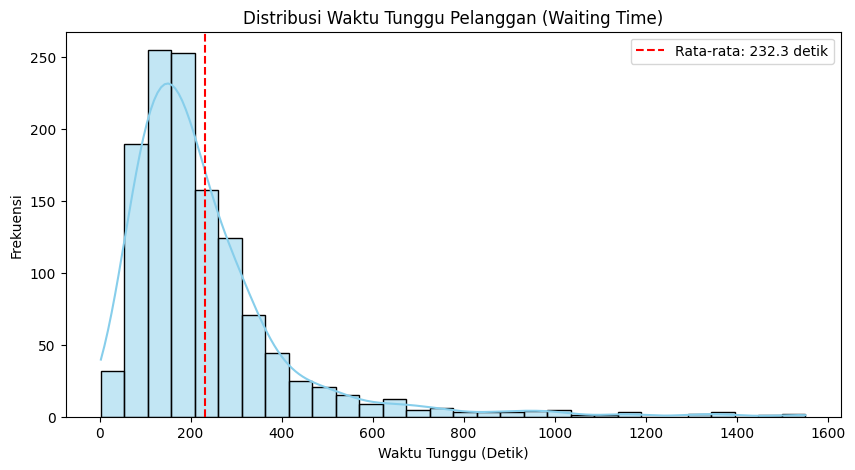

In [9]:
plt.figure(figsize=(10, 5))
sns.histplot(df_clean["Waiting Time Seconds"], bins=30, kde=True, color="skyblue")
plt.axvline(df_clean["Waiting Time Seconds"].mean(), color="red", linestyle="--", label=f'Rata-rata: {df_clean["Waiting Time Seconds"].mean():.1f} detik')
plt.title("Distribusi Waktu Tunggu Pelanggan (Waiting Time)")
plt.xlabel("Waktu Tunggu (Detik)")
plt.ylabel("Frekuensi")
plt.legend()
plt.show()

## Kesimpulan & Insight Utama

Berdasarkan hasil analisis data operasional call center di atas, berikut adalah insight utama yang ditemukan:

1. **Kinerja Penanganan Panggilan (Answer Rate)**
   - Dari total **248,373** panggilan masuk, sebanyak **89.07%** (221,234 panggilan) berhasil dijawab dengan baik.
   - Namun, terdapat **27,139 panggilan yang diabaikan/terputus (Abandoned)** (sekitar **10.93%**). Ini adalah angka kehilangan pelanggan yang cukup besar dan perlu ditekan.

2. **Masalah Waktu Tunggu yang Kritis (Waiting Time)**
   - Pelanggan rata-rata harus menunggu selama **232.31 detik (hampir 4 menit)** sebelum panggilan mereka terhubung ke agen.
   - Ini berbanding terbalik dengan kecepatan menjawab agen (`Answer Speed`) yang rata-rata sangat cepat yaitu **24.90 detik** setelah terhubung.
   - **Rekomendasi**: Lamanya waktu tunggu mengindikasikan adanya antrean panjang. Perusahaan disarankan menambah jumlah agen pada jam sibuk (peak hours) atau mengoptimalkan sistem IVR (Interactive Voice Response).

3. **Tingkat Layanan (Service Level)**
   - Rata-rata *Service Level* dalam 20 detik hanya mencapai **70.87%**. Di industri call center, standar optimal biasanya berada di kisaran 80%. Ini menunjukkan perlunya perbaikan dalam alokasi staf agen.